In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("social_media_sentiment data.csv")

In [3]:
df.head()

,post_id,post_text,post_date,platform,hashtags,likes,comments,shares
0,10001,The event starts at 6 PM.,2026-05-08 10:51:00,Instagram,#Tutorial #Learning,6.0,9.0,3.0
1,10002,"Love the new product, excellent quality!",2026-09-01 10:30:00,YouTube,#Video,142.0,27.0,29.0
2,10003,"Love the new product, excellent quality!",2026-06-10 21:03:00,YouTube,NaN,131.0,12.0,37.0
3,10004,The event starts at 6 PM.,2026-07-16 18:45:00,Instagram,#Tutorial #Learning,81.0,11.0,11.0
4,10005,The new update was released today.,2026-10-08 09:19:00,Instagram,#CustomerService,115.0,7.0,0.0


In [4]:
df.shape

(1003, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   post_id    1003 non-null   int64  
 1   post_text  992 non-null    object 
 2   post_date  993 non-null    object 
 3   platform   995 non-null    object 
 4   hashtags   967 non-null    object 
 5   likes      982 non-null    float64
 6   comments   987 non-null    float64
 7   shares     986 non-null    float64
dtypes: float64(3), int64(1), object(4)
memory usage: 62.8+ KB


In [6]:
df.describe()

,post_id,likes,comments,shares
count,1003.000000,982.000000,987.000000,986.000000
mean,10490.814556,90.215886,16.830800,14.158215
std,282.735980,59.544245,9.642638,11.743507
min,10001.000000,0.000000,0.000000,0.000000
25%,10247.500000,42.000000,9.000000,4.000000
50%,10490.000000,87.000000,17.000000,13.000000
75%,10736.500000,132.000000,24.000000,22.000000
max,10983.000000,283.000000,48.000000,55.000000


In [7]:
df.duplicated().sum()

np.int64(24)

In [8]:
df["platform"].value_counts()

platform
Instagram    377
Facebook     343
YouTube      275
Name: count, dtype: int64

In [9]:
df.isnull().sum()

post_id       0
post_text    11
post_date    10
platform      8
hashtags     36
likes        21
comments     16
shares       17
dtype: int64

In [10]:
df["post_text"].isnull().sum()

np.int64(11)

In [11]:
df_clean = df.copy()

In [12]:
df_clean = df_clean.drop_duplicates()

In [13]:
df_clean.isnull().sum()

post_id       0
post_text    11
post_date    10
platform      8
hashtags     36
likes        21
comments     15
shares       17
dtype: int64

In [14]:
df_clean = df_clean.dropna(subset=["post_text"])

In [15]:
df_clean["post_text"] = df_clean["post_text"].str.strip()

In [16]:
df_clean["hashtags"] = df_clean["hashtags"].fillna("No Hashtag")

In [17]:
df_clean["platform"] = df_clean["platform"].fillna(
    df_clean["platform"].mode()[0]
)

In [18]:
df_clean["post_date"] = pd.to_datetime(
    df_clean["post_date"], errors="coerce"
)

In [19]:
numeric_cols = ["likes", "comments", "shares"]

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [20]:

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Original Shape: (1003, 8)
Cleaned Shape: (968, 8)


In [21]:
print(df_clean.isnull().sum())

post_id       0
post_text     0
post_date    10
platform      0
hashtags      0
likes         0
comments      0
shares        0
dtype: int64


In [22]:
print(df_clean.duplicated().sum())

0


In [23]:
df_clean.duplicated().sum()

np.int64(0)

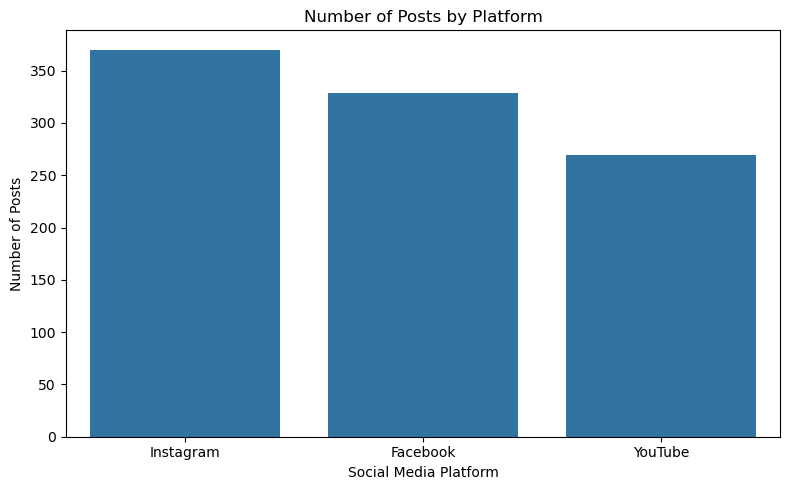

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="platform",
    order=df_clean["platform"].value_counts().index
)

plt.title("Number of Posts by Platform")
plt.xlabel("Social Media Platform")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Engagement Statistics:


,likes,comments,shares
count,968.000000,968.000000,968.000000
mean,89.795455,16.713843,14.161157
std,59.079683,9.549725,11.617876
min,0.000000,0.000000,0.000000
25%,42.750000,9.000000,4.000000
50%,86.000000,17.000000,13.000000
75%,131.000000,23.000000,22.000000
max,283.000000,48.000000,55.000000


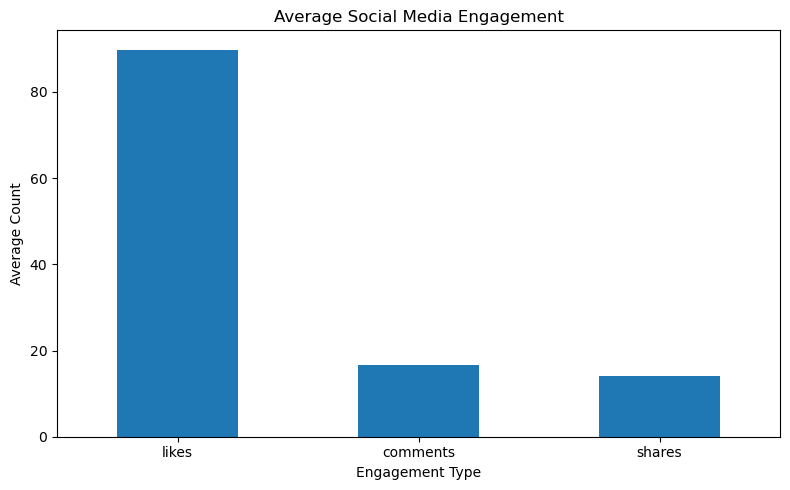

In [25]:

engagement_cols = ["likes", "comments", "shares"]

print("Engagement Statistics:")
display(df_clean[engagement_cols].describe())

df_clean[engagement_cols].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Social Media Engagement")
plt.xlabel("Engagement Type")
plt.ylabel("Average Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


               likes   comments     shares
platform                                  
Facebook   92.765957  16.534954  14.808511
Instagram  86.816216  16.689189  14.391892
YouTube    90.260223  16.966543  13.052045


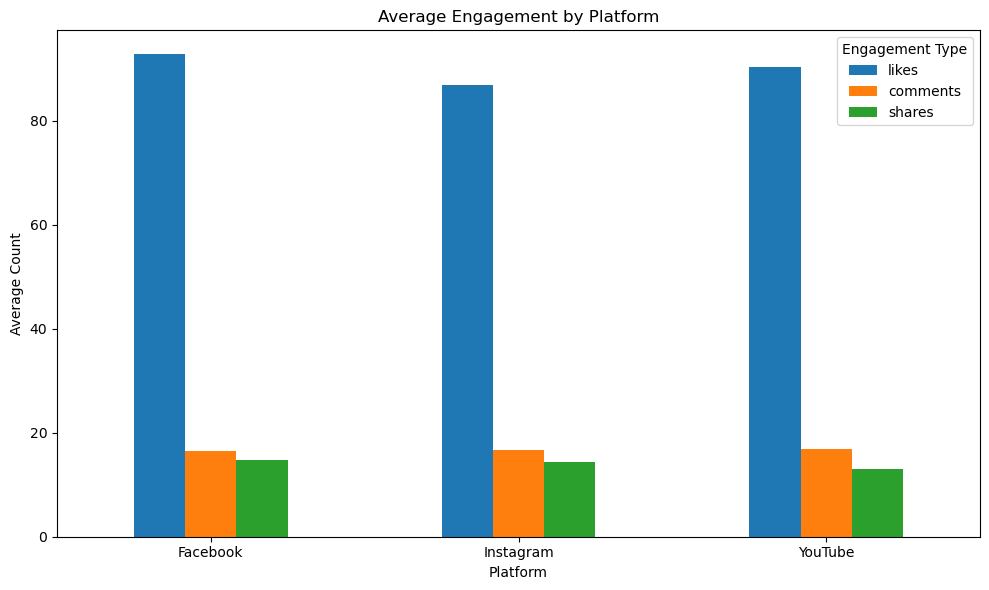

In [26]:

platform_engagement = df_clean.groupby("platform")[
    ["likes", "comments", "shares"]
].mean()

print(platform_engagement)

platform_engagement.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Engagement by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Count")
plt.xticks(rotation=0)
plt.legend(title="Engagement Type")
plt.tight_layout()
plt.show()


In [27]:
%pip install textblob



   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 5.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [31]:
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(str(text)).sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

df_clean["sentiment"] = df_clean["post_text"].apply(get_sentiment) 

display(df_clean[["post_text", "sentiment"]].head(15))

,post_text,sentiment
0,The event starts at 6 PM.,Neutral
1,"Love the new product, excellent quality!",Positive
2,"Love the new product, excellent quality!",Positive
3,The event starts at 6 PM.,Neutral
4,The new update was released today.,Positive
5,Great experience from start to finish.,Positive
6,The announcement is available online.,Positive
7,Customer support did not solve my problem.,Neutral
8,I am unhappy with this purchase.,Negative
9,Fantastic service and quick response.,Positive


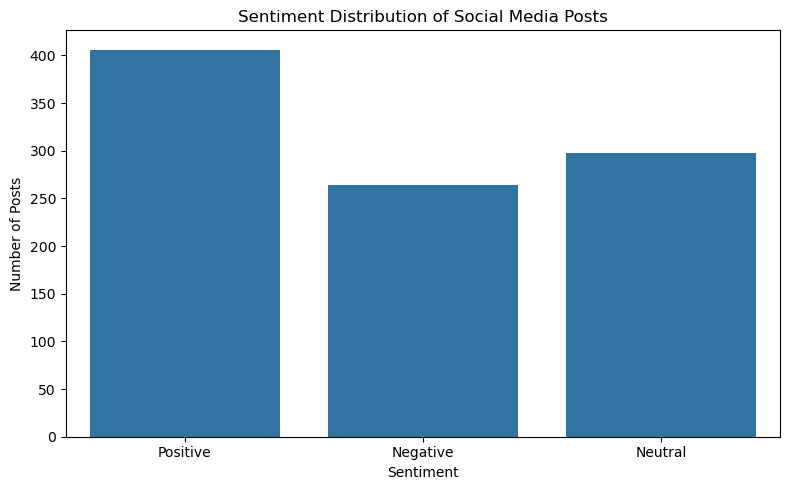

In [32]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="sentiment",
    order=["Positive", "Negative", "Neutral"]
)

plt.title("Sentiment Distribution of Social Media Posts")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()


In [33]:
platform_sentiment = pd.crosstab(
    df_clean["platform"],
    df_clean["sentiment"]
)

print(platform_sentiment)


sentiment  Negative  Neutral  Positive
platform                              
Facebook         91       94       144
Instagram        92      127       151
YouTube          81       77       111


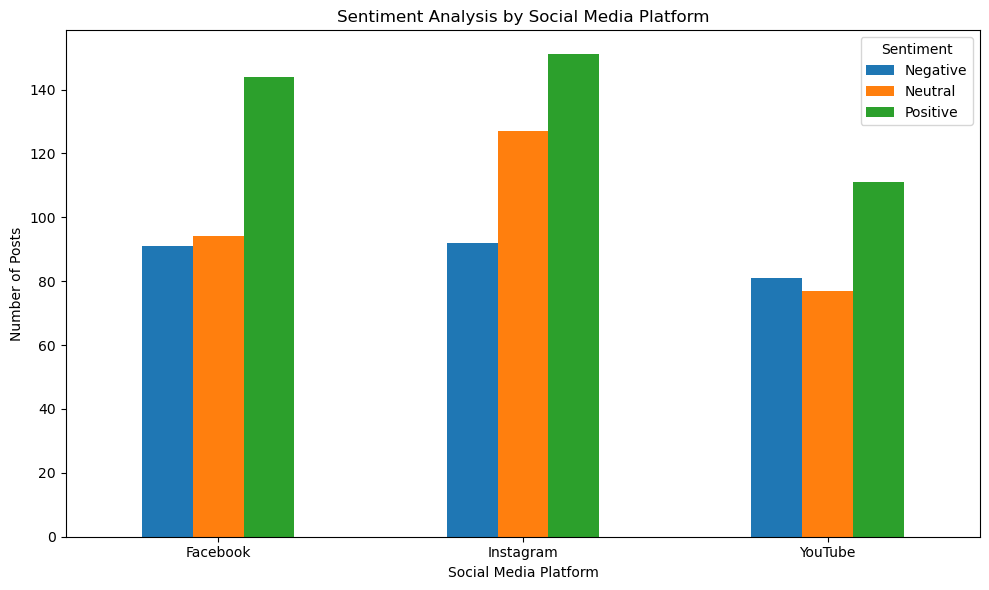

In [34]:
platform_sentiment.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Analysis by Social Media Platform")
plt.xlabel("Social Media Platform")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

            likes  comments  shares
sentiment                          
Negative    45.62     23.46    6.44
Neutral     75.30     10.89   10.11
Positive   129.16     16.61   22.15


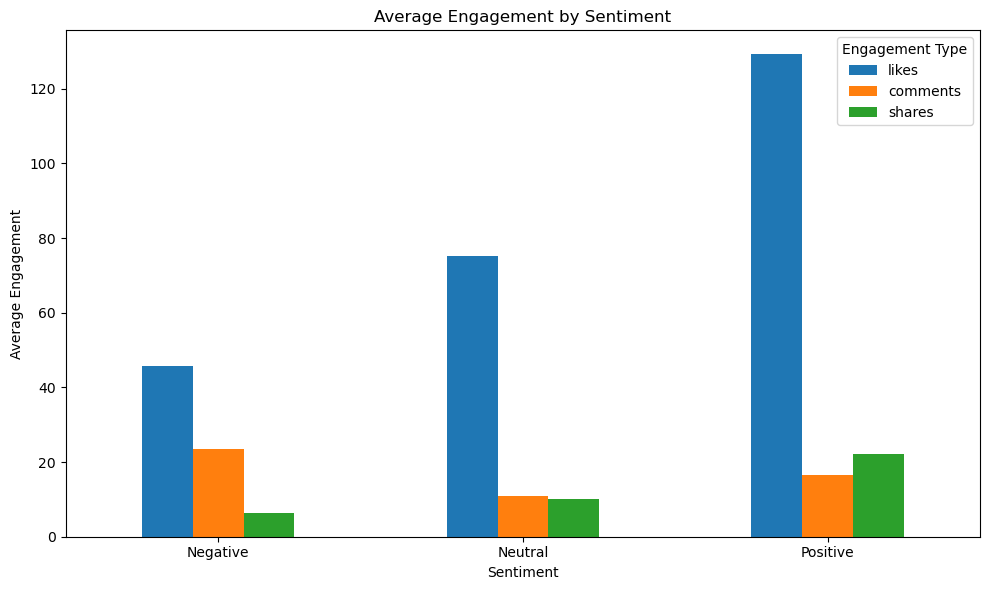

In [35]:

sentiment_engagement = df_clean.groupby("sentiment")[
    ["likes", "comments", "shares"]
].mean().round(2)

print(sentiment_engagement)

sentiment_engagement.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Engagement by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Engagement")
plt.xticks(rotation=0)
plt.legend(title="Engagement Type")
plt.tight_layout()
plt.show()


In [36]:

df_clean.to_csv(
    "sentiment_analysis_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [37]:
print("Final Dataset Shape:", df_clean.shape)

Final Dataset Shape: (968, 9)


In [38]:
print(df_clean["sentiment"].value_counts())

sentiment
Positive    406
Neutral     298
Negative    264
Name: count, dtype: int64


In [40]:
df_clean["platform"].value_counts()

platform
Instagram    370
Facebook     329
YouTube      269
Name: count, dtype: int64

In [41]:
print(df_clean.isnull().sum())

post_id       0
post_text     0
post_date    10
platform      0
hashtags      0
likes         0
comments      0
shares        0
sentiment     0
dtype: int64


In [42]:
display(df_clean.head())

,post_id,post_text,post_date,platform,hashtags,likes,comments,shares,sentiment
0,10001,The event starts at 6 PM.,2026-05-08 10:51:00,Instagram,#Tutorial #Learning,6.0,9.0,3.0,Neutral
1,10002,"Love the new product, excellent quality!",2026-09-01 10:30:00,YouTube,#Video,142.0,27.0,29.0,Positive
2,10003,"Love the new product, excellent quality!",2026-06-10 21:03:00,YouTube,No Hashtag,131.0,12.0,37.0,Positive
3,10004,The event starts at 6 PM.,2026-07-16 18:45:00,Instagram,#Tutorial #Learning,81.0,11.0,11.0,Neutral
4,10005,The new update was released today.,2026-10-08 09:19:00,Instagram,#CustomerService,115.0,7.0,0.0,Positive


In [43]:
output_file = "sentiment_analysis_powerbi.csv"

df_clean.to_csv(output_file, index=False)

print("Power BI dataset exported:", output_file)

Power BI dataset exported: sentiment_analysis_powerbi.csv
